pedi ao codex para pegar na confusão que eu tinha feito
e organizar tudo
isto é o resultado:

# Analise do MCTS para PopOut

Este notebook organiza a analise experimental das variantes de Monte Carlo Tree Search (MCTS) implementadas para o jogo PopOut. O objetivo nao e apresentar apenas resultados isolados, mas sim definir claramente que dados sao recolhidos, como sao recolhidos, e como esses dados justificam a escolha final do agente.

O notebook original de exploracao foi mantido separado. Este notebook e uma versao organizada para analise e discussao.

## Objetivo da analise

A parte de MCTS do trabalho deve responder a tres perguntas principais:

1. Como o numero de filhos considerados em cada no afeta a qualidade das jogadas e o tempo de decisao?
2. Como o numero de iteracoes do MCTS afeta o desempenho?
3. As estrategias usadas durante a simulacao, como procurar vitorias imediatas ou reutilizar a arvore, melhoram o agente?

Estas perguntas estao alinhadas com o enunciado, que pede a implementacao de MCTS com UCT e a exploracao de diferentes numeros de filhos e outras estrategias.

## MCTS implementado

O MCTS implementado segue as quatro fases classicas:

1. **Selecao**: a arvore e percorrida escolhendo filhos com maior valor UCT.
2. **Expansao**: quando existe um filho ainda nao explorado, esse estado e adicionado a arvore.
3. **Simulacao**: a partir do novo estado, e jogada uma partida simulada ate um estado terminal.
4. **Retropropagacao**: o resultado da simulacao e propagado ate a raiz, atualizando visitas e vitorias.

A formula UCT usada e:

$$
UCT = \frac{wins}{visits} + c \sqrt{\frac{\log(parent\_visits)}{visits}}
$$

Esta formula tenta equilibrar exploracao de jogadas pouco visitadas com aproveitamento de jogadas que ja tiveram bons resultados.

## Metodologia experimental

Para comparar variantes, os agentes sao colocados a jogar uns contra os outros. Para reduzir o enviesamento causado pela ordem de jogo, cada par e testado nas duas ordens: `A vs B` e `B vs A`.

Para cada variante sao recolhidos os seguintes dados:

- numero de vitorias;
- numero de empates;
- numero de derrotas;
- `win_rate`, isto e, vitorias / total de jogos;
- `draw_rate`, isto e, empates / total de jogos;
- `loss_rate`, isto e, derrotas / total de jogos;
- `score`, calculado como `(vitorias + 0.5 * empates) / total de jogos`;
- tempo medio por jogada.

O `score` e usado porque um empate e melhor do que uma derrota, mas pior do que uma vitoria. Como o MCTS usa simulacoes aleatorias, os resultados devem ser interpretados como tendencias empiricas, nao como garantias absolutas.

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from game import Game
from players import MCTS

random.seed(42)
np.random.seed(42)

## Funcoes auxiliares

As funcoes seguintes correm torneios entre variantes, agregam as metricas e produzem tabelas/graficos. Ficam definidas antes das experiencias para que o notebook possa ser executado de cima para baixo sem erros.

In [2]:
def variants_stats(variants, n_games=5):
    """Run pairwise matches between MCTS variants.

    Each pair is tested in both orders: A vs B and B vs A.
    The function returns aggregated results per variant.
    """
    stats = {}
    for name, _ in variants:
        stats[name] = {
            "wins": 0,
            "draws": 0,
            "losses": 0,
            "avg_time_sum": 0.0,
        }

    for i in range(len(variants)):
        for j in range(i + 1, len(variants)):
            ordered_pairs = [
                (variants[i], variants[j]),
                (variants[j], variants[i]),
            ]

            for (p1_name, p1_mcts), (p2_name, p2_mcts) in ordered_pairs:
                for _ in range(n_games):
                    # Reset roots so each game starts from an independent tree.
                    p1_mcts.root = None
                    p2_mcts.root = None

                    result = Game("", "").notebook_run(
                        p1_name,
                        p1_mcts.move,
                        p2_name,
                        p2_mcts.move,
                    )

                    stats[p1_name]["avg_time_sum"] += result["avg_time_player1"]
                    stats[p2_name]["avg_time_sum"] += result["avg_time_player2"]

                    if result["winner"] == 1:
                        stats[p1_name]["wins"] += 1
                        stats[p2_name]["losses"] += 1
                    elif result["winner"] == -1:
                        stats[p2_name]["wins"] += 1
                        stats[p1_name]["losses"] += 1
                    else:
                        stats[p1_name]["draws"] += 1
                        stats[p2_name]["draws"] += 1

    for name in stats:
        total = stats[name]["wins"] + stats[name]["draws"] + stats[name]["losses"]
        stats[name]["total_games"] = total
        stats[name]["win_rate"] = stats[name]["wins"] / total if total else 0
        stats[name]["draw_rate"] = stats[name]["draws"] / total if total else 0
        stats[name]["loss_rate"] = stats[name]["losses"] / total if total else 0
        stats[name]["score"] = (stats[name]["wins"] + 0.5 * stats[name]["draws"]) / total if total else 0
        stats[name]["avg_time_per_move"] = stats[name]["avg_time_sum"] / total if total else 0

    return stats


def stats_dataframe(stats):
    """Convert the stats dictionary into a sorted dataframe."""
    df = pd.DataFrame.from_dict(stats, orient="index")
    cols = [
        "wins",
        "draws",
        "losses",
        "total_games",
        "win_rate",
        "draw_rate",
        "loss_rate",
        "score",
        "avg_time_per_move",
    ]
    return df[cols].sort_values(["score", "avg_time_per_move"], ascending=[False, True])


def plot_bars_for_each_var(stats, title):
    variants = list(stats.keys())
    measurements = [
        ("Wins", [stats[v]["wins"] for v in variants], "#2ca02c"),
        ("Draws", [stats[v]["draws"] for v in variants], "#ff7f0e"),
        ("Losses", [stats[v]["losses"] for v in variants], "#d62728"),
    ]

    x = np.arange(len(variants))
    width = 0.22

    fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
    for idx, (label, values, color) in enumerate(measurements):
        rects = ax.bar(x + width * idx, values, width, label=label, color=color)
        ax.bar_label(rects, padding=3)

    ax.set_ylabel("Numero de jogos")
    ax.set_title(title)
    ax.set_xticks(x + width, variants, rotation=35, ha="right")
    ax.legend(loc="upper right", ncols=3)
    plt.show()


def plot_score_vs_time(stats, title):
    names = list(stats.keys())
    times = [stats[name]["avg_time_per_move"] for name in names]
    scores = [stats[name]["score"] for name in names]

    plt.figure(figsize=(8, 5))
    plt.scatter(times, scores)

    for name, x, y in zip(names, times, scores):
        plt.annotate(name, (x, y), textcoords="offset points", xytext=(5, 5))

    plt.xlabel("Tempo medio por jogada (s)")
    plt.ylabel("Score")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.show()

## Experiencia 1: numero de filhos considerados

Nesta experiencia compara-se o MCTS sem limite de filhos com variantes que consideram apenas 2, 4 ou 8 filhos por no.

Dados recolhidos:

- vitorias, empates e derrotas de cada variante;
- `score` final de cada variante;
- tempo medio por jogada.

Interpretacao esperada: limitar filhos pode reduzir o custo de pesquisa, mas tambem pode excluir jogadas importantes, porque a escolha dos filhos e aleatoria.

In [ ]:
child_variants_300 = [
    ("all_300", MCTS(max_iter=300)),
    ("child_2_300", MCTS(child_limit=2, max_iter=300)),
    ("child_4_300", MCTS(child_limit=4, max_iter=300)),
    ("child_8_300", MCTS(child_limit=8, max_iter=300)),
]

stats_children_300 = variants_stats(child_variants_300, n_games=10)
stats_dataframe(stats_children_300)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
all_300,51,0,9,60,0.850000,0.0,0.150000,0.850000,0.141804
child_8_300,43,0,17,60,0.716667,0.0,0.283333,0.716667,0.138573
child_4_300,20,0,40,60,0.333333,0.0,0.666667,0.333333,0.134833
child_2_300,6,0,54,60,0.100000,0.0,0.900000,0.100000,0.126678


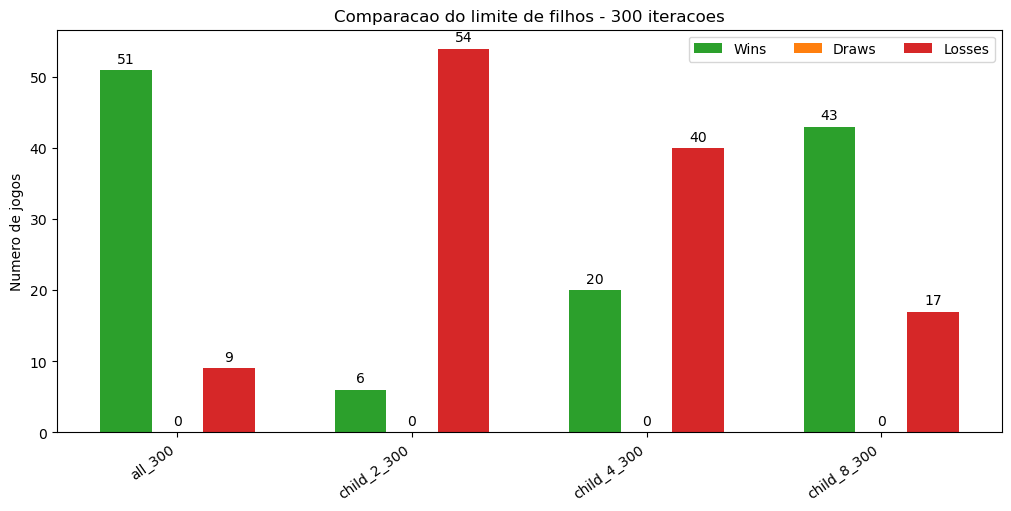

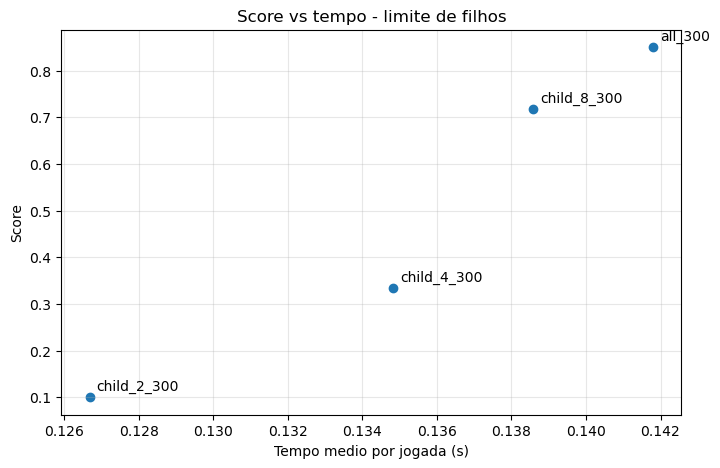

In [ ]:
plot_bars_for_each_var(stats_children_300, "Comparacao do limite de filhos - 300 iteracoes")
plot_score_vs_time(stats_children_300, "Score vs tempo - limite de filhos")

### Discussao da experiencia 1

Depois de executar as celulas anteriores, discutir aqui:

- qual variante teve melhor `score`;
- se houve reducao relevante no tempo medio por jogada;
- se limitar para 2 ou 4 filhos prejudicou demasiado a qualidade;
- se `child_8` parece um compromisso aceitavel entre exploracao e tempo.

Texto possivel para adaptar:

> Os resultados indicam que limitar muito o numero de filhos pode reduzir a diversidade de jogadas exploradas. Como os filhos sao escolhidos aleatoriamente antes de aplicar UCT, limites baixos podem remover jogadas promissoras. Assim, a escolha de um limite so e justificavel se trouxer uma reducao clara do tempo de decisao.

## Experiencia 2: numero de iteracoes

Nesta experiencia analisa-se o efeito do numero de iteracoes no desempenho. Comparam-se variantes com 100, 300 e 500 iteracoes, usando sempre o par `all` vs `child_8`.

Dados recolhidos:

- resultado de `all` contra `child_8` para cada numero de iteracoes;
- tempo medio por jogada;
- score de cada variante.

Interpretacao esperada: aumentar iteracoes deve aumentar o tempo de decisao. A melhoria de desempenho pode nao ser linear, porque as simulacoes continuam a ter uma componente aleatoria.

In [ ]:
iter_variants = {
    100: [
        ("all_100", MCTS(max_iter=100)),
        ("child_8_100", MCTS(child_limit=8, max_iter=100)),
    ],
    300: [
        ("all_300", MCTS(max_iter=300)),
        ("child_8_300", MCTS(child_limit=8, max_iter=300)),
    ],
    500: [
        ("all_500", MCTS(max_iter=500)),
        ("child_8_500", MCTS(child_limit=8, max_iter=500)),
    ],
}

stats_iter = {}
for n_iter, variants in iter_variants.items():
    stats_iter[n_iter] = variants_stats(variants, n_games=10)

iter_rows = []
for n_iter, stats in stats_iter.items():
    for name, values in stats.items():
        iter_rows.append({
            "iterations": n_iter,
            "variant": name,
            "wins": values["wins"],
            "draws": values["draws"],
            "losses": values["losses"],
            "score": values["score"],
            "avg_time_per_move": values["avg_time_per_move"],
        })

pd.DataFrame(iter_rows)

,iterations,variant,wins,draws,losses,score,avg_time_per_move
0,100,all_100,12,0,8,0.60,0.053362
1,100,child_8_100,8,0,12,0.40,0.054578
2,300,all_300,12,0,8,0.60,0.144859
3,300,child_8_300,8,0,12,0.40,0.140602
4,500,all_500,13,0,7,0.65,0.211433
5,500,child_8_500,7,0,13,0.35,0.215540


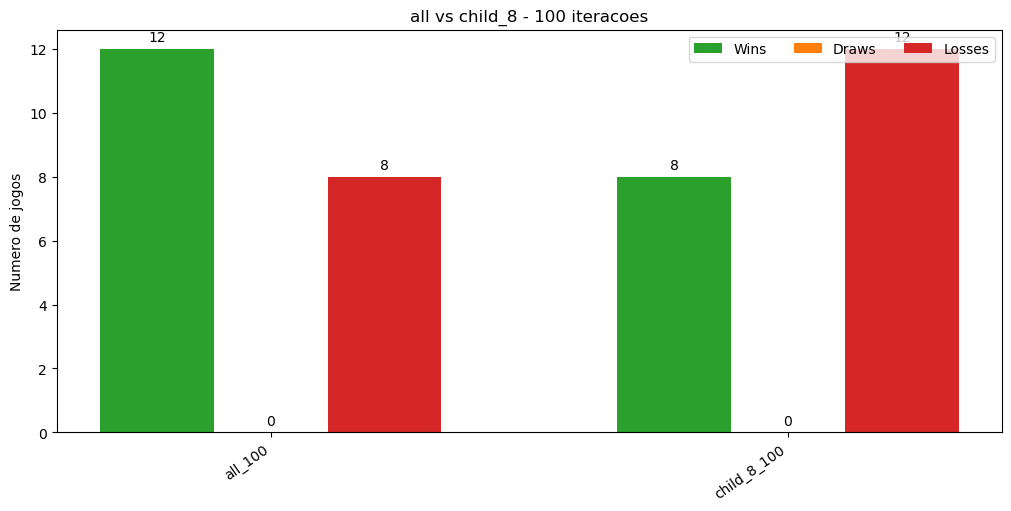

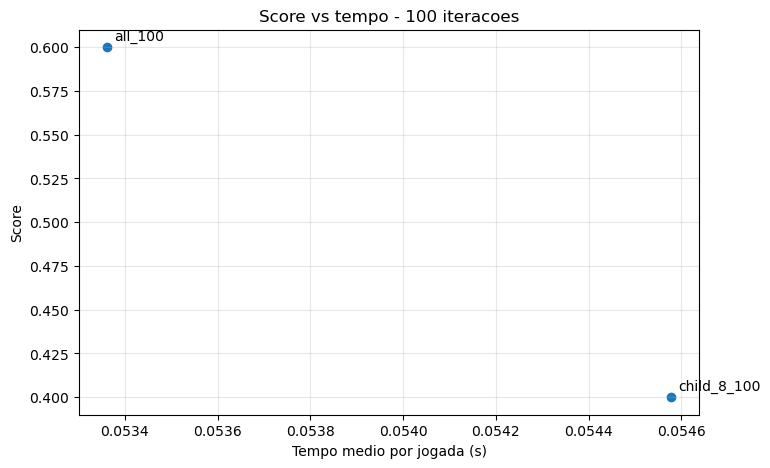

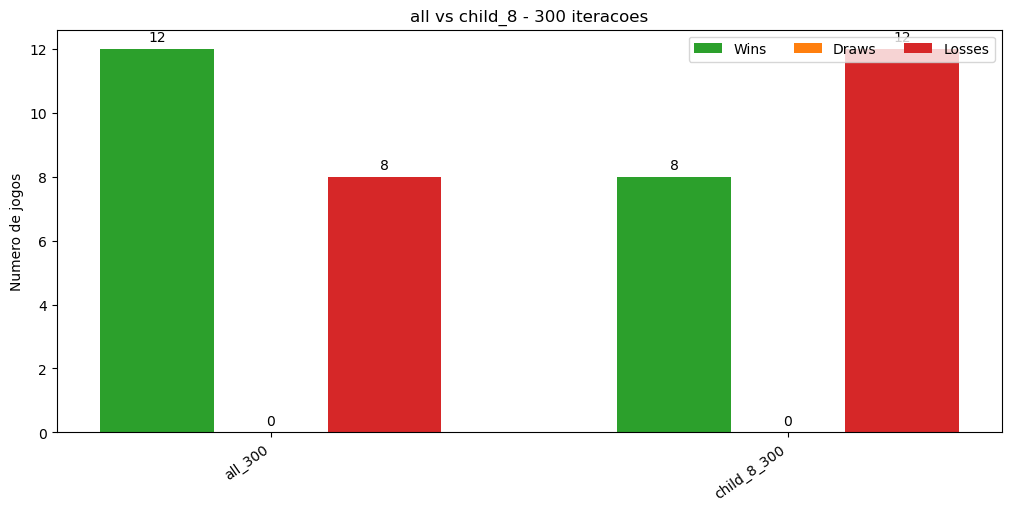

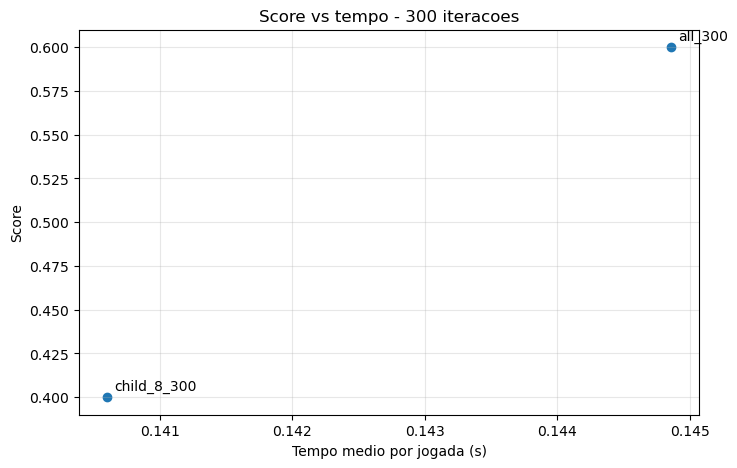

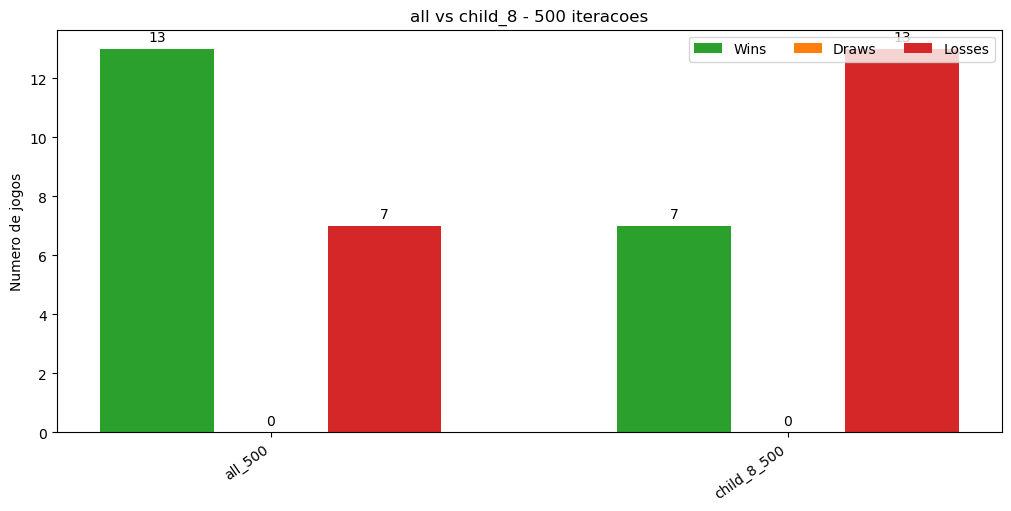

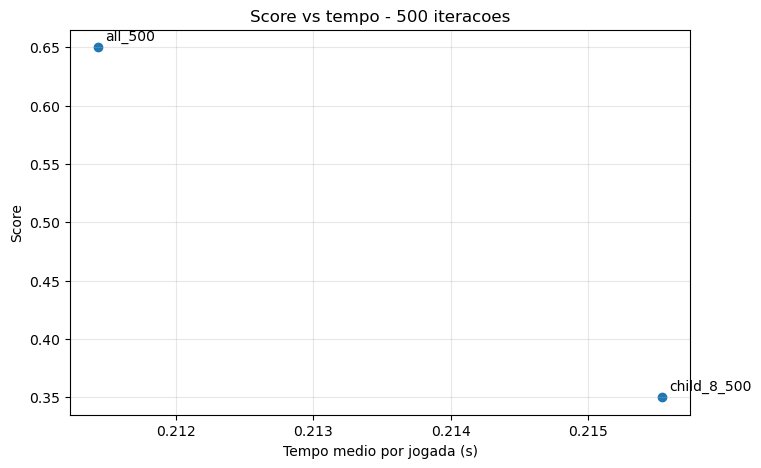

In [ ]:
for n_iter, stats in stats_iter.items():
    plot_bars_for_each_var(stats, f"all vs child_8 - {n_iter} iteracoes")
    plot_score_vs_time(stats, f"Score vs tempo - {n_iter} iteracoes")

### Discussao da experiencia 2

Depois de executar as celulas anteriores, discutir aqui:

- se 500 iteracoes melhoraram claramente o score face a 300;
- se o aumento de tempo compensa;
- se 300 iteracoes sao um compromisso razoavel para as restantes experiencias.

Texto possivel para adaptar:

> O aumento do numero de iteracoes aumenta o custo por jogada. No entanto, a melhoria no resultado nao e necessariamente proporcional, porque a qualidade das simulacoes tambem depende da politica de rollout. Por isso, 300 iteracoes foram usadas como compromisso entre tempo de execucao e qualidade de decisao.

## Experiencia 3: estrategias na simulacao e reutilizacao da arvore

Nesta experiencia sao comparadas variantes que alteram a forma como o MCTS simula jogos ou reutiliza informacao entre jogadas.

Variantes principais:

- `base`: simulacao aleatoria;
- `win`: durante a simulacao, se existir uma jogada que vence imediatamente, essa jogada e escolhida;
- `tree`: reutiliza a arvore entre jogadas;
- `win_tree`: combina a heuristica de vitoria imediata com reutilizacao da arvore.

A estrategia `block`, que evita jogadas que permitem vitoria imediata ao adversario, tambem pode ser testada, mas tende a ser mais lenta porque avalia respostas possiveis do oponente durante a simulacao.

In [7]:
heuristic_light_300 = [
    ("base_300", MCTS(max_iter=300)),
    ("win_300", MCTS(max_iter=300, heuristic_win=True)),
    ("tree_300", MCTS(max_iter=300, save_tree=True)),
    ("win_tree_300", MCTS(max_iter=300, heuristic_win=True, save_tree=True)),
]

stats_heuristic_300 = variants_stats(heuristic_light_300, n_games=10)
stats_dataframe(stats_heuristic_300)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
win_tree_300,42,0,18,60,0.700000,0.0,0.300000,0.700000,0.075490
win_300,38,0,22,60,0.633333,0.0,0.366667,0.633333,0.077023
tree_300,22,0,38,60,0.366667,0.0,0.633333,0.366667,0.132291
base_300,18,0,42,60,0.300000,0.0,0.700000,0.300000,0.138685


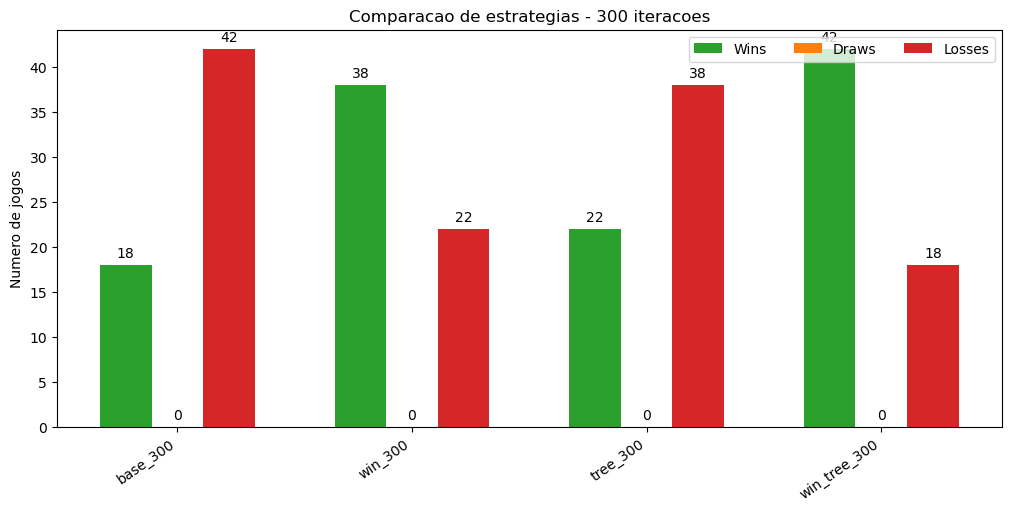

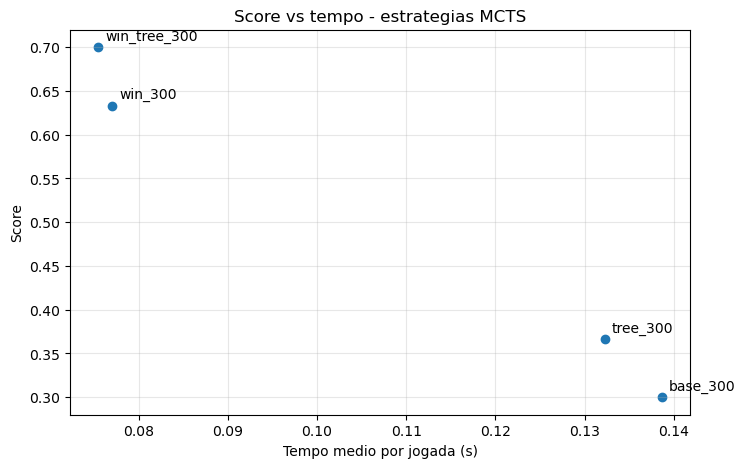

In [8]:
plot_bars_for_each_var(stats_heuristic_300, "Comparacao de estrategias - 300 iteracoes")
plot_score_vs_time(stats_heuristic_300, "Score vs tempo - estrategias MCTS")

### Teste opcional da estrategia block

A estrategia `block` e mais pesada, porque para cada jogada possivel durante a simulacao tambem verifica se o adversario pode ganhar logo a seguir. Por isso, esta experiencia deve ser usada como teste complementar, com menos jogos ou menos iteracoes.

Se o tempo for demasiado alto, esta estrategia pode ser mencionada como uma abordagem testada mas nao escolhida para a variante final devido ao custo computacional.

In [9]:
heuristic_with_block_100 = [
    ("base_100", MCTS(max_iter=100)),
    ("win_100", MCTS(max_iter=100, heuristic_win=True)),
    ("block_100", MCTS(max_iter=100, heuristic_block_win=True)),
    ("win_block_100", MCTS(max_iter=100, heuristic_win=True, heuristic_block_win=True)),
    ("full_100", MCTS(max_iter=100, heuristic_win=True, heuristic_block_win=True, save_tree=True)),
]

stats_block_100 = variants_stats(heuristic_with_block_100, n_games=5)
stats_dataframe(stats_block_100)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
win_100,33,0,7,40,0.825,0.0,0.175,0.825,0.028780
win_block_100,29,0,11,40,0.725,0.0,0.275,0.725,1.024101
full_100,17,0,23,40,0.425,0.0,0.575,0.425,1.113363
base_100,12,0,28,40,0.300,0.0,0.700,0.300,0.055216
block_100,9,0,31,40,0.225,0.0,0.775,0.225,1.490633


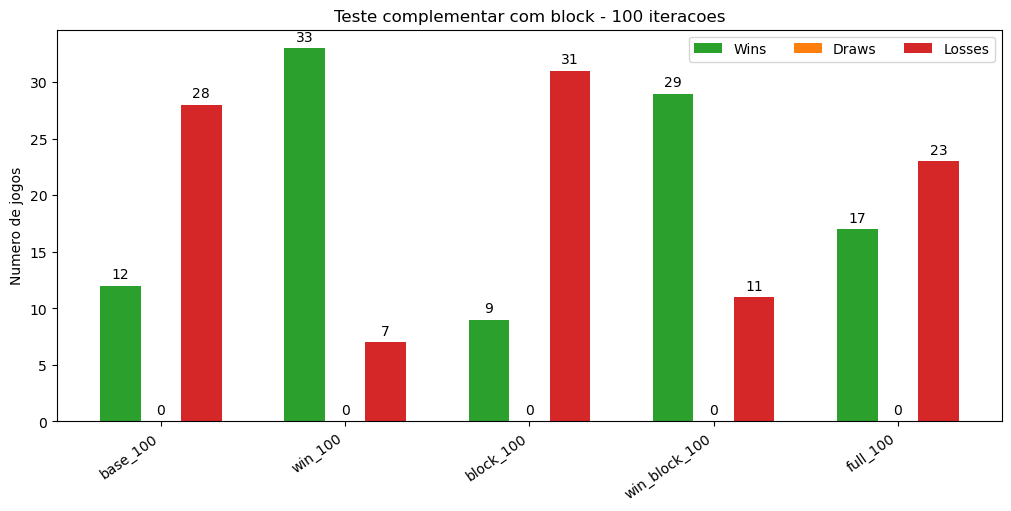

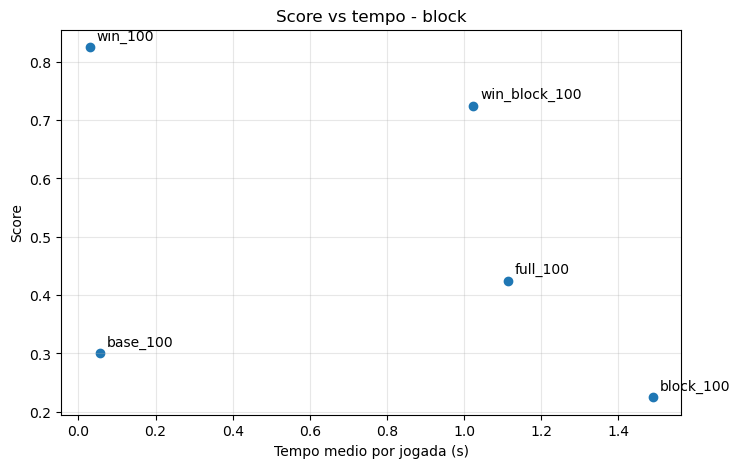

In [10]:
plot_bars_for_each_var(stats_block_100, "Teste complementar com block - 100 iteracoes")
plot_score_vs_time(stats_block_100, "Score vs tempo - block")

### Discussao da experiencia 3

Depois de executar as celulas anteriores, discutir aqui:

- se `win` melhorou o score face ao `base`;
- se `tree` reduziu tempo ou melhorou resultado;
- se `win_tree` foi a variante mais equilibrada;
- se `block` teve custo demasiado alto para justificar a sua utilizacao.

Texto possivel para adaptar:

> A heuristica `win` torna as simulacoes menos aleatorias, porque aproveita vitorias imediatas quando elas existem. Isto tende a produzir rollouts mais informativos sem acrescentar um custo elevado. A reutilizacao da arvore tambem e relevante em jogos sequenciais, porque parte da pesquisa feita na jogada anterior continua valida depois da resposta do adversario.

## Escolha final do agente

A escolha final deve considerar simultaneamente qualidade e tempo. Uma variante com score ligeiramente superior pode nao ser a melhor se for muito mais lenta.

Criterios para escolher o agente final:

- score competitivo contra as outras variantes;
- tempo medio por jogada aceitavel para jogar contra um humano;
- comportamento coerente com as regras do PopOut;
- simplicidade suficiente para justificar no relatorio e na apresentacao.

Com base nas experiencias, uma escolha natural a avaliar e:

```python
MCTS(max_iter=300, heuristic_win=True, save_tree=True)
```

Se os resultados mostrarem que 500 iteracoes melhoram claramente o desempenho sem tornar o jogo demasiado lento, entao a variante equivalente com 500 iteracoes tambem pode ser considerada.

## Limitacoes da analise

Esta analise tem algumas limitacoes importantes:

- O MCTS e estocastico, logo diferentes execucoes podem produzir resultados diferentes.
- O numero de jogos e limitado pelo tempo de execucao.
- Algumas variantes, especialmente `block`, aumentam bastante o custo das simulacoes.
- Comparacoes com poucos jogos devem ser interpretadas como indicios, nao como prova estatistica forte.

Estas limitacoes devem ser mencionadas no notebook final para mostrar rigor na interpretacao dos resultados.

## Conclusao a preencher apos executar

Resumo sugerido para completar depois de obter os resultados:

- Na experiencia do limite de filhos, a melhor variante foi `...`, com score `...` e tempo medio `...`.
- Na experiencia das iteracoes, `...` iteracoes pareceram o melhor compromisso entre desempenho e tempo.
- Nas estrategias de simulacao, a variante `...` apresentou o melhor equilibrio.
- A variante final escolhida foi `...`, porque `...`.

Conclusao tecnica possivel:

> Os resultados mostram que melhorar a politica de simulacao pode ser tao importante como aumentar o numero de iteracoes. Em particular, escolher vitorias imediatas durante o rollout reduz parte da aleatoriedade das simulacoes e ajuda o MCTS a estimar melhor o valor das jogadas. A reutilizacao da arvore tambem e uma estrategia adequada para PopOut, pois permite aproveitar informacao de pesquisas anteriores ao longo da partida.